In [1]:
"""
    Analysis of the MALDI spectrum
"""

__author__  = "Pierre-Alexandre HO"
__date__    = "2025-09-02"
__version__ = "1.0"

import os
import pandas as pd
import polars as pl
import plotly.express as px
import numpy as np

import matplotlib.pyplot as plt
from pathlib import Path

# TODO: Change spectrum name f'Spectrum_{i} in parse_spectra by the file name
# TODO: Add prgress bar


In [2]:


def read_spectrum(file: str, sep: str = ','):
    """
    Lazy reading of the spectrum file....

    Args:
        file (str): _description_
        sep (str, optional): _description_. Defaults to ','.

    Returns:
        _type_: _description_
    """
    return (
        pl.scan_csv(file, separator=sep)
        .select([
            pl.col("m/z"),       # Colonne des masses (clé de jointure)
            pl.col("Intensity")  # Colonne d'intensité renommée
        ])
    )


def parse_spectra(dir: str, files:list):
    spectra = {}
    for i, file in enumerate(files):
        spectrum_path = os.path.join(dir, file)
        spectra[f'Spectrum_{i}'] = read_spectrum(spectrum_path)
    return spectra


def plot_spectrum(spectrum):
    fig = px.line(spectrum, x='m/z', y='Intensity')
    fig.write_html("../data/output_test.html")
    fig.show


In [3]:
dir = "../data/standards/"
files = [f for f in os.listdir(dir) if f.endswith(".csv")]
spectra = parse_spectra(dir, files)

spectr_0 = (spectra['Spectrum_0']
            #.filter(pl.col('m/z')>800)
            #.filter(pl.col('m/z')<2000)
            .collect())
mean = spectr_0.select(pl.col('Intensity').mean().alias("mean"))
print(mean)

print(spectr_0)
#plot_spectrum(spectr_0)

shape: (1, 1)
┌──────────────┐
│ mean         │
│ ---          │
│ f64          │
╞══════════════╡
│ 31727.269212 │
└──────────────┘
shape: (1_834_767, 2)
┌─────────────┬───────────┐
│ m/z         ┆ Intensity │
│ ---         ┆ ---       │
│ f64         ┆ f64       │
╞═════════════╪═══════════╡
│ 500.514765  ┆ 4984.59   │
│ 500.515004  ┆ 4699.41   │
│ 500.515243  ┆ 4163.71   │
│ 500.515481  ┆ 4129.75   │
│ 500.51572   ┆ 4831.31   │
│ …           ┆ …         │
│ 3999.92301  ┆ 27359.84  │
│ 3999.938252 ┆ 30764.9   │
│ 3999.953495 ┆ 38632.98  │
│ 3999.968737 ┆ 46225.67  │
│ 3999.98398  ┆ 49650.53  │
└─────────────┴───────────┘


C:\Users\Utilisateur\AppData\Local\Temp\ipykernel_15284\449244854.py:10: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



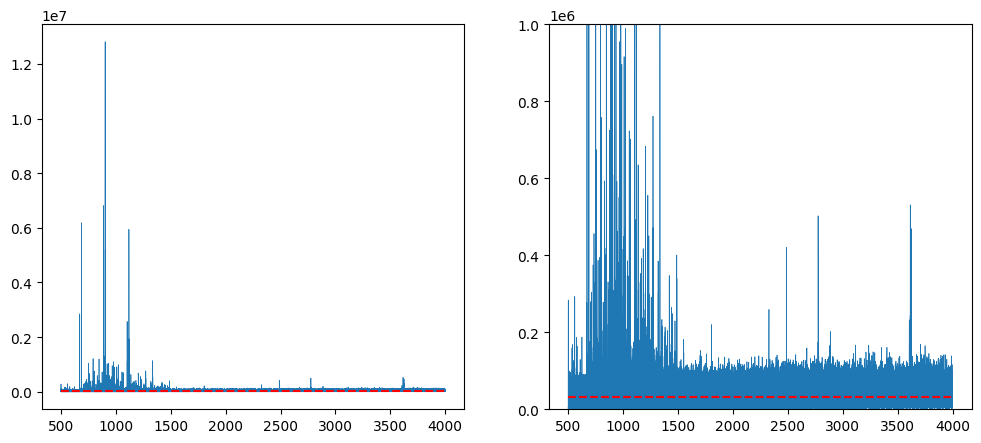

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
ax[0].plot(spectr_0['m/z'], spectr_0['Intensity'],linewidth=0.5)
ax[0].hlines(y=mean, xmin=spectr_0['m/z'].min(), xmax=spectr_0['m/z'].max(),
          colors='r', linestyles='dashed', label='Mean Intensity')

ax[1].plot(spectr_0['m/z'], spectr_0['Intensity'],linewidth=0.5)
ax[1].hlines(y=mean, xmin=spectr_0['m/z'].min(), xmax=spectr_0['m/z'].max(),
          colors='r', linestyles='dashed', label='Mean Intensity')
ax[1].set_ylim(0,0.1*10**7)
fig.show()

In [28]:
from scipy.signal import find_peaks as fp

array([     1,      4,      6, ..., 156787, 156790, 156793],
      shape=(50715,))

In [103]:
# Note obliger de passer en monde .collect et plus en lazy
spectr_0 = spectra['Spectrum_0'].collect()  # en mode lazy
peaks, _ = fp(x= spectr_0["Intensity"])  # index of max peak
spectr_0 = spectr_0[peaks]
mean_peak = spectr_0.select(pl.col('Intensity').mean().alias('mean')).item()
med_peak = spectr_0.select(pl.col('Intensity').median().alias('mean')).item()
spectr_0


m/z,Intensity
f64,f64
500.516675,6809.91
500.518823,23075.85
500.522164,13027.23
500.524789,19119.2
500.52646,25309.43
…,…
3999.2677,65927.99
3999.374364,14424.9
3999.54199,59646.6


In [104]:
print(f"Mean: {mean_peak} / Median {med_peak}")

Mean: 41750.56319370392 / Median 38409.405


C:\Users\Utilisateur\AppData\Local\Temp\ipykernel_15284\2205904833.py:12: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



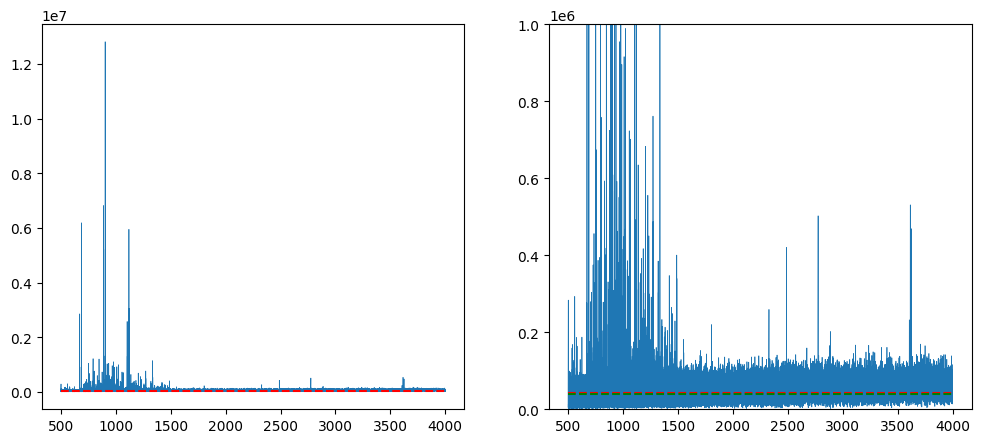

In [105]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
ax[0].plot(spectr_0['m/z'], spectr_0['Intensity'],linewidth=0.5)
ax[0].hlines(y=mean_peak, xmin=spectr_0['m/z'].min(), xmax=spectr_0['m/z'].max(),
          colors='r', linestyles='dashed', label='Mean Intensity')

ax[1].plot(spectr_0['m/z'], spectr_0['Intensity'],linewidth=0.5)
ax[1].hlines(y=mean_peak, xmin=spectr_0['m/z'].min(), xmax=spectr_0['m/z'].max(),
          colors='r', linestyles='dashed', label='Mean Intensity')
ax[1].hlines(y=med_peak, xmin=spectr_0['m/z'].min(), xmax=spectr_0['m/z'].max(),
          colors='g', linestyles='dashed', label='Mean Intensity')
ax[1].set_ylim(0,0.1*10**7)
fig.show()

Soustraction de la moyenne des peak max aux datas brut en mode lazy pour optimizer les performance
- si <= 0 ==> I = 0
- si > 0 ==> I = resultats de la soustraction

In [91]:
spectr_0 = spectra['Spectrum_0']  # en mode lazy

spectr_0 = spectr_0.with_columns(
    pl.when(pl.col("Intensity") - mean_peak <= 0)
      .then(0)
      .otherwise(pl.col("Intensity") - mean_peak)
      .alias("trunc_intensity")
).collect()
# spectr_0 = spectr_0.with_columns(
#     (pl.col("Intensity") - mean_peak).alias("intensity_minus_mean")
# )

C:\Users\Utilisateur\AppData\Local\Temp\ipykernel_15284\3444416366.py:7: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



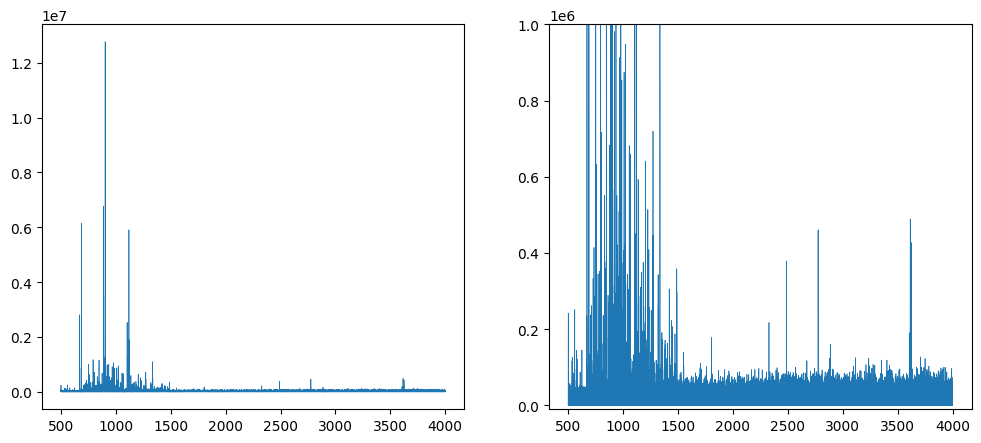

In [92]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
ax[0].plot(spectr_0['m/z'], spectr_0['trunc_intensity'],linewidth=0.5)


ax[1].plot(spectr_0['m/z'], spectr_0['trunc_intensity'],linewidth=0.5)
ax[1].set_ylim(-0.001*10**7,0.1*10**7)
fig.show()

Normalization sur la valeur des pic maxs

C:\Users\Utilisateur\AppData\Local\Temp\ipykernel_15284\1485431427.py:24: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



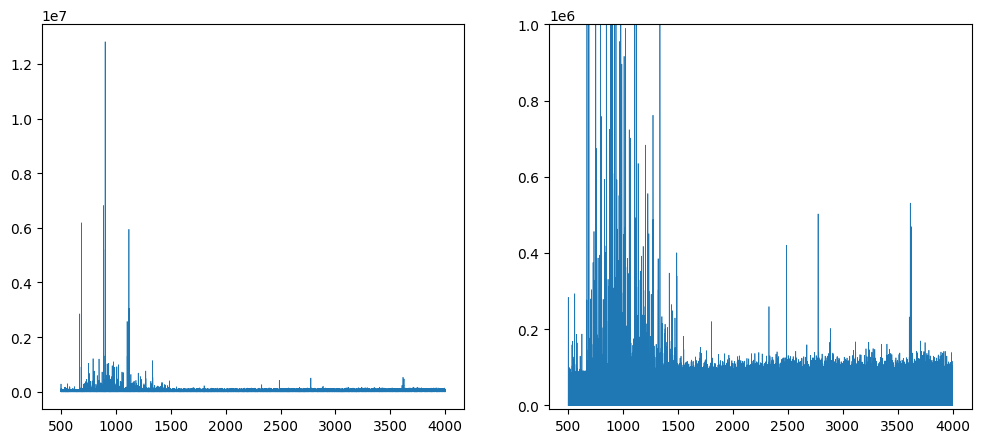

In [98]:
spectr_0 = spectra['Spectrum_0'].collect()  # en mode lazy

# Note obliger de passer en monde .collect et plus en lazy
peaks, _ = fp(x= spectr_0["Intensity"])  # index of max peak
spectr_0 = spectr_0[peaks]
mean_peak = spectr_0.select(pl.col('Intensity').mean().alias('mean')).item()
std_peak = spectr_0.select(pl.col('Intensity').std().alias('std')).item()


spectr_0 = spectr_0.with_columns(
    pl.when(pl.col("Intensity") - mean_peak <= 0)
      .then(0)
      .otherwise(pl.col("Intensity") - mean_peak / std_peak)
      .alias("Normalized")
)


fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
ax[0].plot(spectr_0['m/z'], spectr_0['Normalized'],linewidth=0.5)


ax[1].plot(spectr_0['m/z'], spectr_0['Normalized'],linewidth=0.5)
ax[1].set_ylim(-0.001*10**7,0.1*10**7)
fig.show()


Normalization min max

C:\Users\Utilisateur\AppData\Local\Temp\ipykernel_15284\766647483.py:23: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



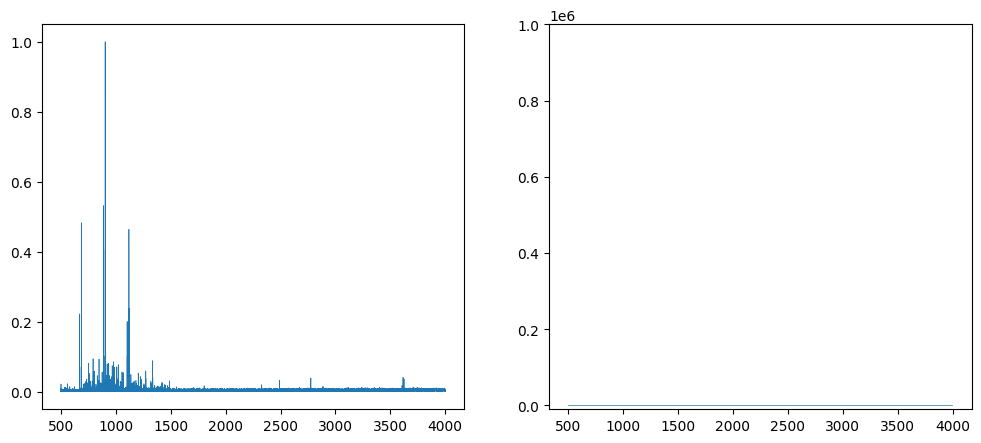

In [102]:
spectr_0 = spectra['Spectrum_0'].collect()  # en mode lazy

# Note obliger de passer en monde .collect et plus en lazy
peaks, _ = fp(x= spectr_0["Intensity"])  # index of max peak
spectr_0 = spectr_0[peaks]
mean_peak = spectr_0.select(pl.col('Intensity').mean().alias('mean')).item()
std_peak = spectr_0.select(pl.col('Intensity').std().alias('std')).item()


spectr_0 = spectr_0.with_columns(
    (
        (pl.col("Intensity") - pl.col("Intensity").min()) /
        (pl.col("Intensity").max() - pl.col("Intensity").min())
    ).alias("Normalized")
)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
ax[0].plot(spectr_0['m/z'], spectr_0['Normalized'],linewidth=0.5)


ax[1].plot(spectr_0['m/z'], spectr_0['Normalized'],linewidth=0.5)
ax[1].set_ylim(-0.001*10**7,0.1*10**7)
fig.show()


Test avec le quantil Q3

C:\Users\Utilisateur\AppData\Local\Temp\ipykernel_15284\4212023635.py:23: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



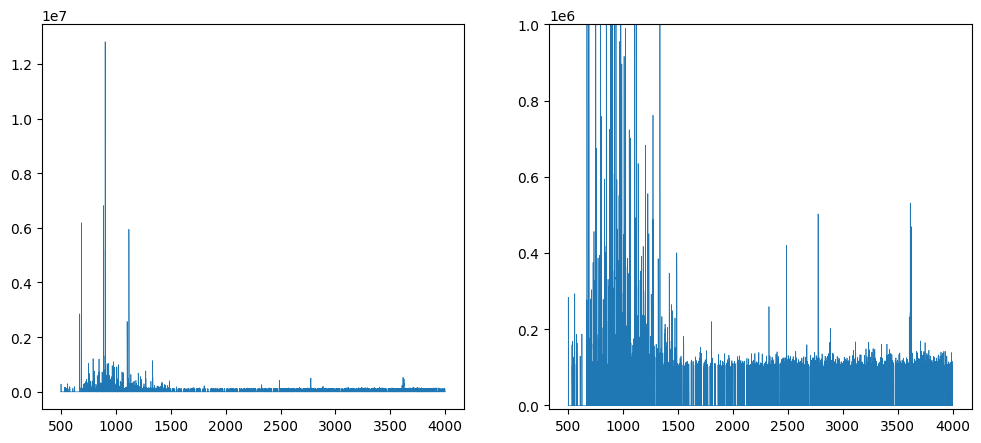

In [113]:
spectr_0 = spectra['Spectrum_0'].collect()  # en mode lazy

# Note obliger de passer en monde .collect et plus en lazy
peaks, _ = fp(x= spectr_0["Intensity"])  # index of max peak
spectr_0 = spectr_0[peaks]

q75 = spectr_0.select(
    pl.col("Intensity").quantile(0.99).alias("q75")
).item()

spectr_0 = spectr_0.with_columns(
    pl.when(pl.col("Intensity") > q75)
      .then(pl.col("Intensity"))
      .otherwise(0)
      .alias("Filtered")
)
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
ax[0].plot(spectr_0['m/z'], spectr_0['Filtered'],linewidth=0.5)


ax[1].plot(spectr_0['m/z'], spectr_0['Filtered'],linewidth=0.5)
ax[1].set_ylim(-0.001*10**7,0.1*10**7)
fig.show()



C:\Users\Utilisateur\AppData\Local\Temp\ipykernel_15284\4036586652.py:14: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



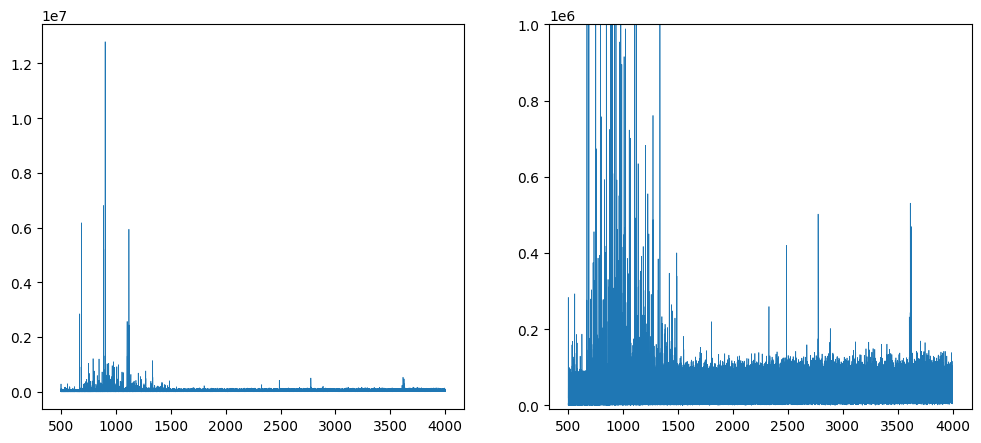

In [115]:
from scipy.signal import savgol_filter

spectr_0 = spectra['Spectrum_0'].collect() 
intensities = spectr_0["Intensity"].to_numpy()
smoothed_intensities_sg = savgol_filter(intensities, window_length=5, polyorder=2)
spectr_0 = spectr_0.with_columns(pl.Series("Intensity_smoothed_SG", smoothed_intensities_sg))

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
ax[0].plot(spectr_0['m/z'], spectr_0['Intensity_smoothed_SG'],linewidth=0.5)


ax[1].plot(spectr_0['m/z'], spectr_0['Intensity_smoothed_SG'],linewidth=0.5)
ax[1].set_ylim(-0.001*10**7,0.1*10**7)
fig.show()




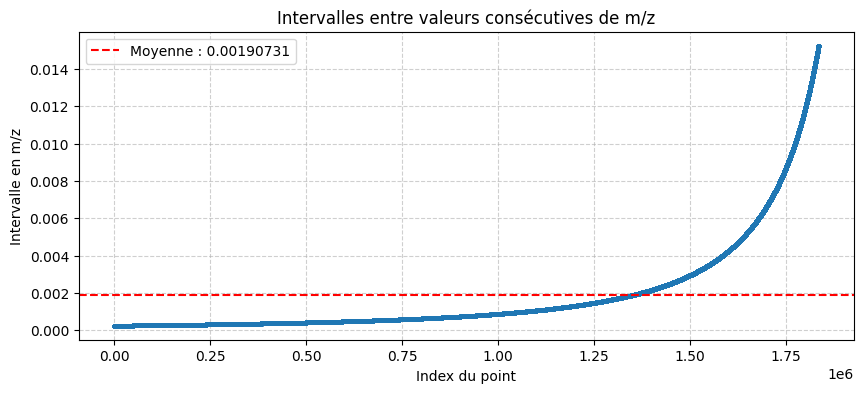

In [4]:
x_all = spectr_0['m/z'].to_numpy()

# Calcul des intervalles
intervals = np.diff(x_all)

# Tracé des intervalles
plt.figure(figsize=(10, 4))
plt.plot(intervals, "o-", markersize=2, linewidth=0.5)
plt.axhline(y=np.mean(intervals), color="r", linestyle="--", label=f"Moyenne : {np.mean(intervals):.8f}")
plt.xlabel("Index du point")
plt.ylabel("Intervalle en m/z")
plt.title("Intervalles entre valeurs consécutives de m/z")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


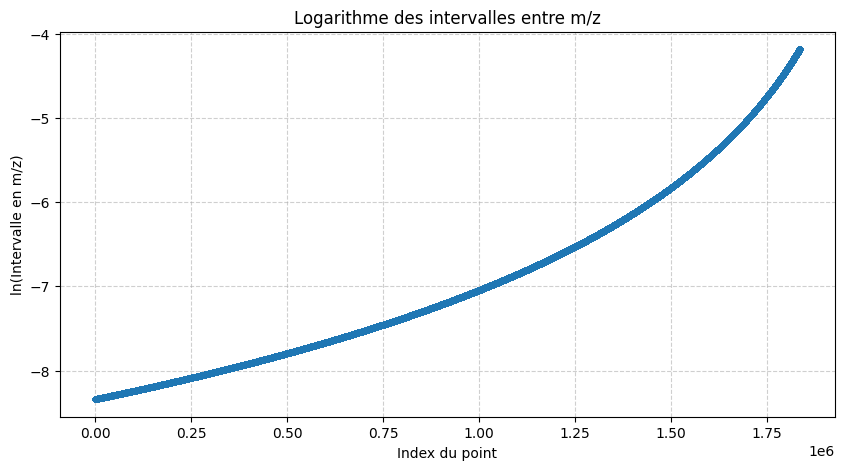

In [5]:
# Tracé en échelle log
plt.figure(figsize=(10, 5))
plt.plot(np.log(intervals), "o-", markersize=3)
plt.xlabel("Index du point")
plt.ylabel("ln(Intervalle en m/z)")
plt.title("Logarithme des intervalles entre m/z")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

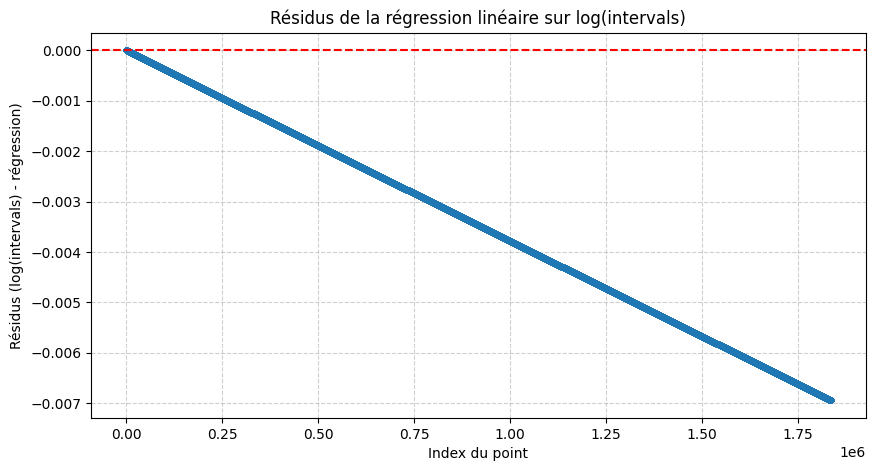

In [ ]:
from scipy.stats import linregress

# Calcul des intervalles et logarithmes
intervals = np.diff(x_all)
log_intervals = np.log(intervals)

# Régression linéaire
x = np.arange(len(intervals))
slope, intercept, _, _, _ = linregress(x, intervals)
fit = slope * x + intercept
residus = intercept - fit

# Tracé des résidus
plt.figure(figsize=(10, 5))
plt.plot(fit, "o-", markersize=3)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Index du point")
plt.ylabel("Résidus (log(intervals) - régression)")
plt.title("Résidus de la régression linéaire sur log(intervals)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()